# Beckmann maps: learning the endpoint

*A hands-on introduction for people who know what a neural network is, have heard of diffusion or flow models, and want to see how a one-step generator can be trained directly.*

Flow and diffusion models generate an image by **integrating a differential equation**: a network is called tens or hundreds of times, and each call moves the sample a little closer to the data. A **Beckmann map** is trained to output the **endpoint** of that journey directly, so generating a sample is **one network call**. No teacher model, no distillation stage: the map is learned from scratch, from the same noise-to-data pairs a flow model uses. This notebook builds the idea up on a toy problem in the plane, where everything can be drawn:

1. the problem: move noise onto data;
2. flow matching, a velocity field that depends on time, and what goes wrong if you take one step;
3. autonomous flows: the time-averaged **Beckmann current**, whose flow lines never cross;
4. the **Beckmann map**: the endpoint of that flow, trained directly without ever integrating;
5. one call versus many steps, on the same noise.

A bonus section at the end shows guidance, the addition that lets the maps scale to ImageNet and text-to-image. Everything runs on a CPU in about ten minutes. Beckmann maps and autonomous flows were introduced in *Beckmann Transport Models* (Lee et al., 2026), work by one of the authors of *Scalable Beckmann Maps* (Unneberg, Wang et al., 2026), which takes the map to ImageNet and text-to-image. The [project page](https://tullebulle.github.io/projects/sbm/) has an interactive version of this tutorial on the same toy, and a live text-to-image demo of a map trained at scale.

In [1]:
import math, time, copy
import numpy as np
import torch
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
torch.set_num_threads(2)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
SAGE, CHARCOAL, INK, GREY = "#1B8A6B", "#4A4A4A", "#2F2A24", "#8F8E88"
print("torch", torch.__version__)

torch 2.9.1+cu128


## 1. The problem: move noise onto data

A generative model turns **noise** into **data**. Noise is cheap, a draw $x_0 \sim \mu_0 = \mathcal N(0, I_d)$; data $x_1 \sim \mu_1$ is what we have examples of: images, or the latent codes of images. We want a map $T$ with

$$T_\#\mu_0 = \mu_1,$$

read "pushing noise through $T$ gives data": if $x_0$ is a fresh noise draw, $T(x_0)$ should be a fresh data sample with the right frequencies.

For an image model, $x$ lives in thousands of dimensions. Here it lives in the plane, and the "dataset" is five points $z_j$ with weights $p_j$ that sum to one. Think of each point as one image and of $p_j$ as how often it appears. A perfect generator sends a fraction $p_j$ of all noise onto the point $z_j$, and nothing anywhere else.

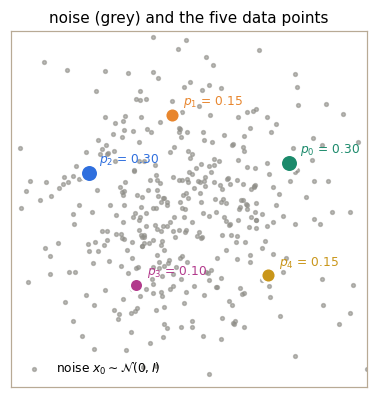

In [2]:
# the toy: five data points on a ring, weights 0.30 / 0.15 / 0.30 / 0.10 / 0.15 (the same toy as the project page)
SPEC = [(25, 1.55, 0.30, "#1B8A6B"), (100, 1.35, 0.15, "#E8862E"), (160, 1.50, 0.30, "#2F6FDE"), (235, 1.30, 0.10, "#B23A8C"), (320, 1.45, 0.15, "#C9961A")]
Z = np.array([[r * math.cos(math.radians(a)), r * math.sin(math.radians(a))] for a, r, p, c in SPEC])
P = np.array([p for a, r, p, c in SPEC]); COL = [c for a, r, p, c in SPEC]; J = len(Z)

def sample_noise(n): return np.random.randn(n, 2)
def sample_data(n):
    k = np.random.choice(J, size=n, p=P); return Z[k], k
def nearest_atom(x): return np.argmin(((x[:, None, :] - Z[None]) ** 2).sum(-1), axis=1)
def basin_masses(x_end):
    k = nearest_atom(x_end); return np.bincount(k, minlength=J) / len(k)
def draw_atoms(ax, label=True):
    for j in range(J): ax.scatter(*Z[j], s=50 + 260 * P[j], color=COL[j], edgecolor="white", lw=1.5, zorder=5)
    if label:
        for j in range(J): ax.annotate(f"$p_{j}$ = {P[j]:.2f}", Z[j], xytext=(7, 7), textcoords="offset points", fontsize=8, color=COL[j])
def frame(ax, title=None, box=2.5):
    ax.set_xlim(-box, box); ax.set_ylim(-box, box); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(True); s.set_color("#B8AA95")
    if title: ax.set_title(title, fontsize=10)

x0 = sample_noise(400)
fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.scatter(*x0.T, s=6, color=GREY, alpha=.6, label=r"noise $x_0 \sim \mathcal{N}(0, I)$")
draw_atoms(ax); frame(ax, "noise (grey) and the five data points")
ax.legend(loc="lower left", fontsize=8, frameon=False); plt.show()

## 2. Interpolants: straight lines from noise to data

Pair every noise draw with a data draw, independently, and join them by a straight line:

$$I_t = (1 - t)\,x_0 + t\,x_1, \qquad \dot I_t = x_1 - x_0, \qquad t \in [0, 1].$$

At $t = 0$ the population of points $I_t$ is the noise cloud, at $t = 1$ it is the data. Write $\rho_t$ for the density of $I_t$. The pairing is random, so a single line is not something we could ever learn, but the **population** moving along these lines is exactly what every method below reproduces, each in its own way.

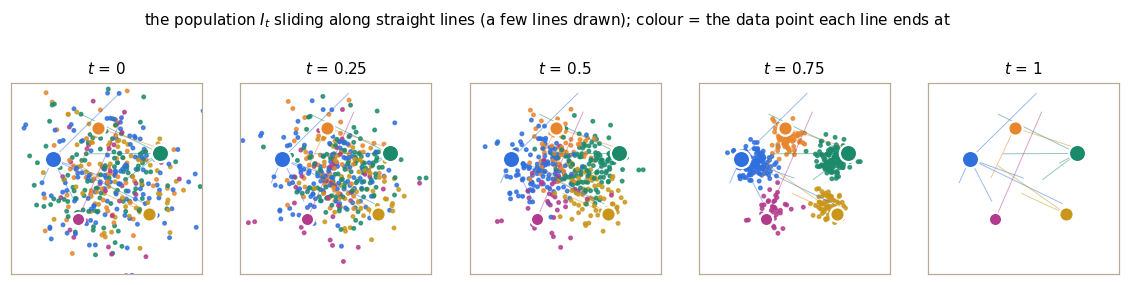

In [3]:
n = 400
x0 = sample_noise(n); x1, k1 = sample_data(n)
fig, axs = plt.subplots(1, 5, figsize=(13, 2.9))
for ax, t in zip(axs, [0, .25, .5, .75, 1]):
    I = (1 - t) * x0 + t * x1
    for i in range(14): ax.plot([x0[i, 0], x1[i, 0]], [x0[i, 1], x1[i, 1]], color=COL[k1[i]], lw=.6, alpha=.5)
    ax.scatter(*I.T, s=5, c=[COL[k] for k in k1], alpha=.8)
    draw_atoms(ax, label=False); frame(ax, f"$t$ = {t}")
fig.suptitle(r"the population $I_t$ sliding along straight lines (a few lines drawn); colour = the data point each line ends at", y=1.02, fontsize=10)
plt.show()

## 3. Flow matching: a velocity that depends on time

**Flow matching** learns the average slope of the lines passing through each point at each time,

$$b_t(x) = \mathbb E\big[\dot I_t \mid I_t = x\big] = \arg\min_{\hat b}\ \int_0^1 \mathbb E\,\big\|\hat b(I_t, t) - \dot I_t\big\|^2\,dt ,$$

a regression with a network that takes the position **and the time** as input. The population $\rho_t$ is carried exactly by the ODE $\dot X_t = b_t(X_t)$ (this is the continuity equation $\partial_t \rho_t + \nabla\cdot(\rho_t b_t) = 0$), so to generate a sample you draw $X_0 \sim \mu_0$ and integrate the ODE from $t = 0$ to $t = 1$, calling the network at every step.

For our toy the regression has a closed form. Given $I_t = x$, the data point was $z_j$ with posterior weight $\propto p_j \exp\!\big(-|x - t z_j|^2 / 2(1-t)^2\big)$, so

$$b_t(x) = \frac{\hat z_t(x) - x}{1 - t}, \qquad \hat z_t(x) = \mathbb E[x_1 \mid I_t = x],$$

the velocity points from $x$ toward the **current best guess of the endpoint** $\hat z_t(x)$ (a "denoiser"), with a speed that grows as time runs out. Early on the guess is vague, so the field points to the middle; late on it has decided.

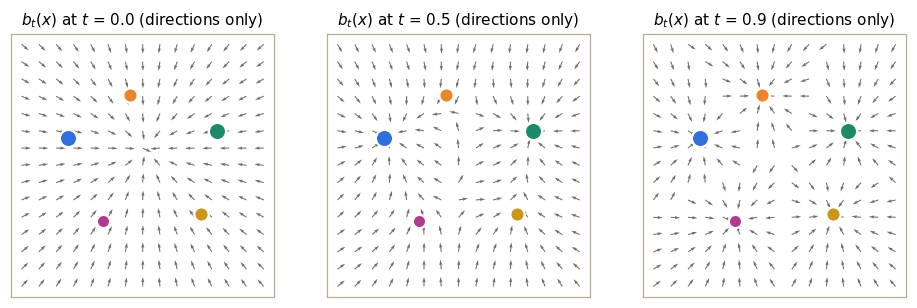

In [4]:
def zhat(x, t):   # E[x1 | I_t = x] for the atoms toy: softmax posterior over the data points
    a = max(1 - t, 1e-6)
    L = np.log(P)[None] - ((x[:, None, :] - t * Z[None]) ** 2).sum(-1) / (2 * a * a)
    w = np.exp(L - L.max(1, keepdims=True)); w /= w.sum(1, keepdims=True)
    return w @ Z
def b_fm(x, t): return (zhat(x, t) - x) / max(1 - t, 1e-6)

g = np.linspace(-2.3, 2.3, 15); GX, GY = np.meshgrid(g, g); pts = np.stack([GX.ravel(), GY.ravel()], 1)
fig, axs = plt.subplots(1, 3, figsize=(10.5, 3.6))
for ax, t in zip(axs, [0.0, 0.5, 0.9]):
    v = b_fm(pts, t); m = np.linalg.norm(v, axis=1, keepdims=True); u = v / (m + 1e-9)
    ax.quiver(pts[:, 0], pts[:, 1], u[:, 0], u[:, 1], color=CHARCOAL, scale=28, width=.004, alpha=.8)
    draw_atoms(ax, label=False); frame(ax, f"$b_t(x)$ at $t$ = {t} (directions only)")
plt.show()

### Train it, then sample with $N$ steps

A small MLP with inputs $(x, t)$ fits the regression in a few seconds. Sampling uses Euler's method with $N$ equal steps: $X_{k+1} = X_k + \tfrac1N\, b_{k/N}(X_k)$. Watch what happens as $N$ shrinks.

In [5]:
class MLP(torch.nn.Module):
    def __init__(self, din, dout, width=128, depth=3):
        super().__init__(); layers = []; d = din
        for _ in range(depth): layers += [torch.nn.Linear(d, width), torch.nn.SiLU()]; d = width
        layers.append(torch.nn.Linear(d, dout)); self.net = torch.nn.Sequential(*layers)
    def forward(self, *args): return self.net(torch.cat(args, -1))

def batch(n):   # one training batch of pairs: x0, x1, t, I_t, dI_t
    x0 = torch.randn(n, 2); x1 = torch.as_tensor(sample_data(n)[0], dtype=torch.float32); t = torch.rand(n, 1)
    return x0, x1, t, (1 - t) * x0 + t * x1, x1 - x0

def fit(loss_fn, params, steps, lr=1e-3, log=1000):
    opt = torch.optim.Adam(params, lr=lr); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr * 1e-2); t0 = time.time()
    for step in range(1, steps + 1):
        loss = loss_fn(step); opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if step % log == 0 or step == steps: print(f"step {step:5d}   loss {loss.item():.4f}   ({time.time() - t0:.0f} s)")

fm = MLP(3, 2)   # input (x, t)
def fm_loss(step):
    x0, x1, t, I, Idot = batch(1024)
    return ((fm(I, t) - Idot) ** 2).sum(-1).mean()
fit(fm_loss, fm.parameters(), 4000)

@torch.no_grad()
def euler(x0, N):
    x = x0.clone()
    for k in range(N):
        x = x + (1 / N) * fm(x, torch.full((len(x), 1), k / N))
    return x

step  1000   loss 2.3143   (3 s)
step  2000   loss 2.1317   (6 s)
step  3000   loss 1.9227   (8 s)
step  4000   loss 2.2288   (11 s)


steps N   mean distance to the nearest data point   basin masses (should be [0.3  0.15 0.3  0.1  0.15] )
      1   1.098   [0.05 0.95 0.   0.   0.  ]
      2   0.696   [0.26 0.36 0.2  0.08 0.11]
      4   0.269   [0.27 0.22 0.27 0.1  0.15]
      8   0.108   [0.27 0.19 0.28 0.1  0.16]
     32   0.044   [0.27 0.16 0.29 0.1  0.17]


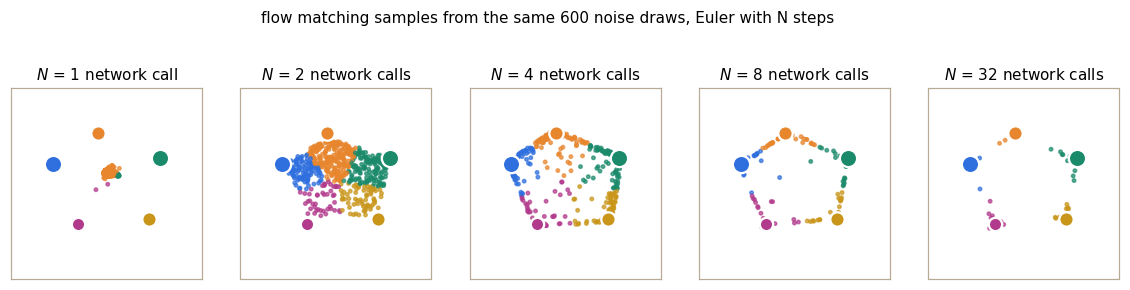

In [6]:
X0 = torch.randn(600, 2)
fig, axs = plt.subplots(1, 5, figsize=(13, 3.0))
print("steps N   mean distance to the nearest data point   basin masses (should be", P, ")")
for ax, N in zip(axs, [1, 2, 4, 8, 32]):
    x = euler(X0, N).numpy(); d = np.sqrt(((x[:, None] - Z[None]) ** 2).sum(-1)).min(1)
    print(f"{N:7d}   {d.mean():.3f}   {np.round(basin_masses(x), 2)}")
    ax.scatter(*x.T, s=5, c=[COL[k] for k in nearest_atom(x)], alpha=.7); draw_atoms(ax, label=False)
    frame(ax, f"$N$ = {N} network call{'s' if N > 1 else ''}")
fig.suptitle("flow matching samples from the same 600 noise draws, Euler with N steps", y=1.02, fontsize=10); plt.show()

With one step every sample lands near the **same point**. That is not a bug: at $t = 0$ nothing is known about the endpoint, so $\hat z_0(x) = \sum_j p_j z_j$ is the data mean for every $x$, and one Euler step moves everything there. For images this is the famous blurry "average image". Flow matching needs many steps because its velocity field keeps changing as $t$ runs; the early steps commit to nothing.

Everything from here on is about learning a generator that is correct in **one** step.

## 4. Autonomous flows: the Beckmann current

**Beckmann Transport Models (BTM)** replace the time-dependent velocity by one field that does not depend on time. Average the flow-matching velocity over time, weighted by how much of the population is at $x$ at each time:

$$J(x) = \int_0^1 \rho_t(x)\, b_t(x)\, dt, \qquad \nu(x) = \int_0^1 \rho_t(x)\, dt, \qquad b(x) = \frac{J(x)}{\nu(x)} .$$

$J$ is the **current**: the net flux of interpolants through $x$. $\nu$ is the **occupation measure**: $\nu(x)\,dx$ is the expected time an interpolant spends in $dx$. Their ratio $b$ is the average velocity of whatever passes through $x$, whenever it passes. The nice thing is that $b$ is the same regression as before with the time input **removed**:

$$b = \arg\min_{\hat b}\ \mathbb E_{t, x_0, x_1}\big\|\hat b(I_t) - \dot I_t\big\|^2 .$$

Integrating the continuity equation $\partial_t \rho_t + \nabla\cdot(\rho_t b_t) = 0$ over $t \in [0,1]$ kills the time derivative except at the ends, $\rho_1 - \rho_0 = \mu_1 - \mu_0$, and leaves

$$\nabla\cdot J = \mu_0 - \mu_1 .$$

Noise is a **source** of current and data a **sink**. This is the flux constraint of Beckmann's continuous transportation problem (1952), hence the name.

**Why a time-independent field changes everything.** The ODE $\dot X = b(X)$ is *autonomous*: through each point passes exactly one flow line, and flow lines never cross or bend back on themselves as $t$ runs, because there is no $t$. So every noise point has a single, well-defined destination. The plane splits into **basins**, one per data point: the set of noise that flows to $z_j$. And the flux constraint fixes how big each basin is. Integrate $\nabla\cdot J$ over a basin $B_j$: $J$ is tangent to the basin's boundary (the boundary is made of flow lines), so no current crosses it, the integral is zero, and

$$\mu_0(B_j) = \mu_1(B_j) = p_j .$$

Each basin carries exactly the mass of its data point. That is the push-forward condition $T_\#\mu_0 = \mu_1$, in one picture.

basin masses of the exact autonomous flow: [0.299 0.156 0.3   0.097 0.148]   data weights: [0.3  0.15 0.3  0.1  0.15]


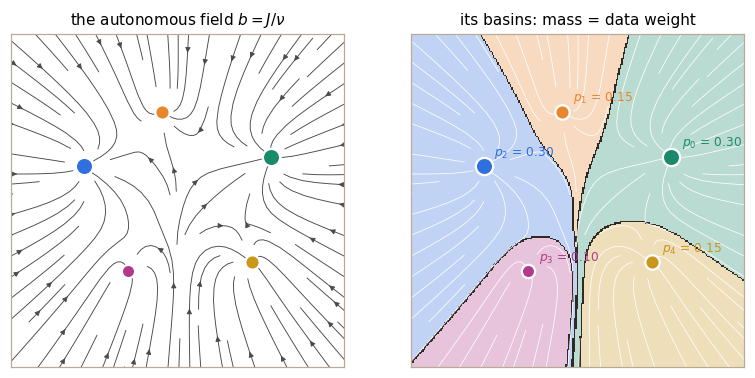

In [7]:
# the exact current of the toy, by quadrature in a = 1 - t on a log grid (rho_t is a Gaussian mixture, so every term is explicit)
NA = 220; AL = np.exp(np.linspace(np.log(1e-4), 0.0, NA)); DL = -np.log(1e-4) / (NA - 1)
def current(x):   # x: (n, 2) -> J (n, 2), nu (n,)
    Jx = np.zeros_like(x); nu = np.zeros(len(x))
    for a in AL:
        for j in range(J):
            d = x - (1 - a) * Z[j]
            rho = P[j] * np.exp(-(d ** 2).sum(-1) / (2 * a * a)) * DL / (2 * np.pi * a)   # rho_t(x) dt with dt = a dlog a
            nu += rho; Jx += rho[:, None] * (Z[j] - x) / a                                 # rho_t b_t dt,  b_t = (z_j - x) / (1 - t) on this pair
    return Jx, nu

G, LO, HI = 129, -3.25, 3.25
gx = np.linspace(LO, HI, G); XX, YY = np.meshgrid(gx, gx, indexing="ij")
Jg, nug = current(np.stack([XX.ravel(), YY.ravel()], 1)); Bg = (Jg / nug[:, None]).reshape(G, G, 2)

def b_auto(x):   # the exact autonomous field b = J / nu, bilinearly interpolated from the grid
    f = np.clip((x - LO) / (HI - LO) * (G - 1), 0, G - 1 - 1e-9); i = f.astype(int); a = f - i
    i0, j0 = i[:, 0], i[:, 1]; ax_, ay_ = a[:, 0:1], a[:, 1:2]
    return (1 - ax_) * ((1 - ay_) * Bg[i0, j0] + ay_ * Bg[i0, j0 + 1]) + ax_ * ((1 - ay_) * Bg[i0 + 1, j0] + ay_ * Bg[i0 + 1, j0 + 1])

def flow_to_end(x, field, dt=0.02, steps=3000, vmin=0.6, vmax=2.2, arrive=0.05):
    # integrate the autonomous ODE from every row of x until it arrives at a data point; the speed is clamped to
    # [vmin, vmax] (an autonomous field's flow lines do not depend on the clock, only on the direction)
    x = x.copy(); dest = -np.ones(len(x), int)
    for _ in range(steps):
        live = np.where(dest < 0)[0]
        if len(live) == 0: break
        p = x[live]; v = field(p); m = np.linalg.norm(v, axis=1, keepdims=True) + 1e-12
        mid = p + 0.5 * dt * np.clip(m, vmin, vmax) / m * v
        v2 = field(mid); m2 = np.linalg.norm(v2, axis=1, keepdims=True) + 1e-12
        p = p + dt * np.clip(m2, vmin, vmax) / m2 * v2; x[live] = p
        d = np.sqrt(((p[:, None] - Z[None]) ** 2).sum(-1)); hit = d.min(1) < arrive
        dest[live[hit]] = d[hit].argmin(1)
    rest = dest < 0
    if rest.any(): dest[rest] = nearest_atom(x[rest])
    return x, dest

# basins on a display grid, and the Gaussian mass of each basin by Monte Carlo
NB = 240; bx = np.linspace(-2.5, 2.5, NB); BX, BY = np.meshgrid(bx, bx, indexing="ij")
_, lab = flow_to_end(np.stack([BX.ravel(), BY.ravel()], 1), b_auto); LAB = lab.reshape(NB, NB)
_, dest_mc = flow_to_end(sample_noise(20000), b_auto); masses_exact = np.bincount(dest_mc, minlength=J) / len(dest_mc)
print("basin masses of the exact autonomous flow:", np.round(masses_exact, 3), "  data weights:", P)

from matplotlib.colors import ListedColormap, to_rgb
TINTS = ListedColormap([tuple(0.3 * c + 0.7 * w for c, w in zip(to_rgb(col), (1, 1, 1))) for col in COL])
def basin_edges(L):   # boundary pixels between basins
    e = np.zeros_like(L, bool); e[1:, :] |= L[1:, :] != L[:-1, :]; e[:, 1:] |= L[:, 1:] != L[:, :-1]; return e

fig, axs = plt.subplots(1, 2, figsize=(8.6, 4.2))
axs[0].streamplot(gx, gx, Bg[..., 0].T, Bg[..., 1].T, color=CHARCOAL, linewidth=.6, density=1.1, arrowsize=.7)
draw_atoms(axs[0], label=False); frame(axs[0], r"the autonomous field $b = J / \nu$")
axs[1].imshow(LAB.T, origin="lower", extent=(-2.5, 2.5, -2.5, 2.5), cmap=TINTS, vmin=-.5, vmax=J - .5, interpolation="nearest")
E = basin_edges(LAB); axs[1].imshow(np.ma.masked_where(~E, E).T, origin="lower", extent=(-2.5, 2.5, -2.5, 2.5), cmap=ListedColormap([INK]), interpolation="nearest")
axs[1].streamplot(gx, gx, Bg[..., 0].T, Bg[..., 1].T, color="white", linewidth=.5, density=1.1, arrowsize=0)
draw_atoms(axs[1]); frame(axs[1], "its basins: mass = data weight")
plt.show()

The streamlines are the whole story of the autonomous flow: no crossings, one destination per point, and basin masses that match the data weights to Monte Carlo precision. You can also learn $b$ with the time-free regression and generate by integrating it, which already gives a few-step sampler. But look at the right panel again: the colouring **is** a one-step generator. Nothing about it needs the arrows.

## 5. The Beckmann map: learn the endpoint

Define $T(x)$ as the data point at the end of the flow line through $x$. By construction $T$ is **constant along flow lines**, and it fixes the data:

$$J(x)\cdot\nabla T(x) = 0 \quad \text{off the data}, \qquad T(x) = x \quad \text{on the data}.$$

This is the **conservation equation** of BTM: $J\cdot\nabla T$ is the derivative of $T$ in the direction of the current, and it must vanish. The key move is to train a network on these two conditions directly, **without ever integrating the flow or even computing $J$**. The transport term enforces conservation with a stop-gradient $\operatorname{sg}$, the boundary term pins the data:

$$\mathcal L(T) = \underbrace{\mathbb E_{t, x_0, x_1}\Big\|T(I_t) - \operatorname{sg}\!\big(T(I_t) + \dot I_t\cdot\nabla T(I_t)\big)\Big\|^2}_{\text{transport}} \;+\; \lambda\, \underbrace{\mathbb E_{x_1}\big\|T(x_1) - x_1\big\|^2}_{\text{boundary}} .$$

Read the transport term as a rule: *look a little way downstream along the line you are on, and move your prediction toward the prediction there.* Its gradient is $-2\,(\dot I_t\cdot\nabla T)\,\partial_\theta T$, so the update stops exactly when the directional derivative $\dot I_t\cdot\nabla T(I_t)$ averages to zero at every point. And averaging $\dot I_t$ over all pairs passing through $x$ at all times is what produced the current:

$$\mathbb E\big[\dot I_t\cdot\nabla T(I_t)\,\big|\, I_t = x\big] \;\text{averaged over } t \text{ with weight } \rho_t \;=\; \frac{J(x)\cdot\nabla T(x)}{\nu(x)} .$$

So the stopped update of random pairs enforces $J\cdot\nabla T = 0$ without anyone computing $J$. The ODE never appears, in training or in sampling: a sample is $T(x_0)$, one call.

In code: draw a batch of pairs, form $I_t$ and $\dot I_t$, get the directional derivative $\dot I_t\cdot\nabla T(I_t)$ with a forward-mode Jacobian-vector product, build the target under `no_grad`, regress. The map is a plain MLP. One practical detail from the paper's recipe: the boundary term as written only ever sees the data points themselves, and a network can fix five points while drifting a little right next to them. So the boundary term also sees *slightly noisy* data, inputs $I_{s'}$ with $s' \in [\gamma, 1]$ close to the data, regressed to the clean $x_1$. The paper calls $\gamma$ the boundary level; we use $\gamma = 0.8$ and give the boundary term a weight $\lambda$.

In [8]:
class Map(torch.nn.Module):
    def __init__(self, dcond=0):
        super().__init__(); self.net = MLP(2 + dcond, 2, depth=4)
    def forward(self, x, *c): return self.net(x, *c)

GAMMA, LAM, LR = 0.8, 1.0, 1e-3       # boundary level, boundary weight, learning rate
def map_batch(n):                      # pairs for the transport term, plus boundary inputs I_s' with s' in [GAMMA, 1]
    x0, x1, t, I, Idot = batch(n); s = GAMMA + (1 - GAMMA) * torch.rand(n, 1)
    return x0, x1, t, I, Idot, (1 - s) * x0 + s * x1

T = Map()
def map_loss(step):
    x0, x1, t, I, Idot, Ib = map_batch(2048)
    with torch.no_grad():
        T_I, dT = torch.func.jvp(T, (I,), (Idot,))     # T(I_t) and the directional derivative dI_t . grad T(I_t)
        target = T_I + dT                                # the stopped target: "the prediction a little downstream"
    transport = ((T(I) - target) ** 2).sum(-1).mean()
    boundary = ((T(Ib) - x1) ** 2).sum(-1).mean()        # noisy boundary inputs, clean targets
    return transport + LAM * boundary
fit(map_loss, T.parameters(), 8000, lr=LR)

step  1000   loss 112.6532   (16 s)
step  2000   loss 70.3768   (33 s)
step  3000   loss 113.8526   (51 s)
step  4000   loss 114.1291   (70 s)
step  5000   loss 191.9623   (89 s)
step  6000   loss 101.8382   (108 s)
step  7000   loss 152.0558   (126 s)
step  8000   loss 209.7462   (145 s)


one-call samples: basin masses [0.273 0.158 0.308 0.1   0.16 ]   data weights [0.3  0.15 0.3  0.1  0.15]
mean distance to the nearest data point 0.099; fraction further than 0.1 away: 0.240
learned basins agree with the exact flow's basins on 97.8 % of the plane


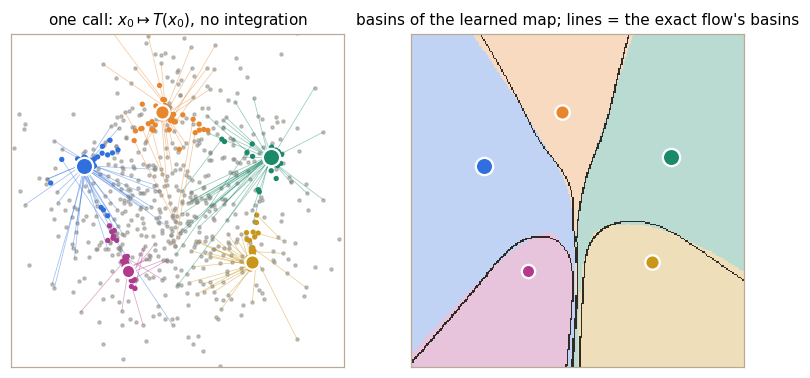

In [9]:
@torch.no_grad()
def one_call(x0): return T(torch.as_tensor(x0, dtype=torch.float32)).numpy()

xs = one_call(X0.numpy()); ks = nearest_atom(xs); dist = np.sqrt(((xs[:, None] - Z[None]) ** 2).sum(-1)).min(1)
print("one-call samples: basin masses", np.round(basin_masses(xs), 3), "  data weights", P)
print(f"mean distance to the nearest data point {dist.mean():.3f}; fraction further than 0.1 away: {(dist > 0.1).mean():.3f}")

grid = np.stack([BX.ravel(), BY.ravel()], 1); Tg = one_call(grid); LAB_T = nearest_atom(Tg).reshape(NB, NB)
agree = (LAB_T == LAB).mean(); print(f"learned basins agree with the exact flow's basins on {100 * agree:.1f} % of the plane")

fig, axs = plt.subplots(1, 2, figsize=(8.6, 4.2))
for i in range(150): axs[0].plot([X0[i, 0], xs[i, 0]], [X0[i, 1], xs[i, 1]], color=COL[ks[i]], lw=.5, alpha=.45)
axs[0].scatter(*X0.numpy().T, s=4, color=GREY, alpha=.5); axs[0].scatter(*xs.T, s=6, c=[COL[k] for k in ks])
draw_atoms(axs[0], label=False); frame(axs[0], r"one call: $x_0 \mapsto T(x_0)$, no integration")
axs[1].imshow(LAB_T.T, origin="lower", extent=(-2.5, 2.5, -2.5, 2.5), cmap=TINTS, vmin=-.5, vmax=J - .5, interpolation="nearest")
axs[1].imshow(np.ma.masked_where(~E, E).T, origin="lower", extent=(-2.5, 2.5, -2.5, 2.5), cmap=ListedColormap([INK]), interpolation="nearest")
draw_atoms(axs[1], label=False); frame(axs[1], "basins of the learned map; lines = the exact flow's basins")
plt.show()

The learned map reproduces the basins of the exact autonomous flow, and it never saw a flow line: training only ever evaluated $T$ and its derivative along random straight lines, plus the boundary term near the data points. Its samples land close to the data points rather than exactly on them (the printout gives the mean distance); a small MLP trained for a minute is still slightly smooth across the basin boundaries. The recipe that makes the map sharp at scale is sketched in section 8.

## 6. One call versus many steps

Same 600 noise draws, three generators. The bar chart scores each by how far its basin masses are from the data weights.

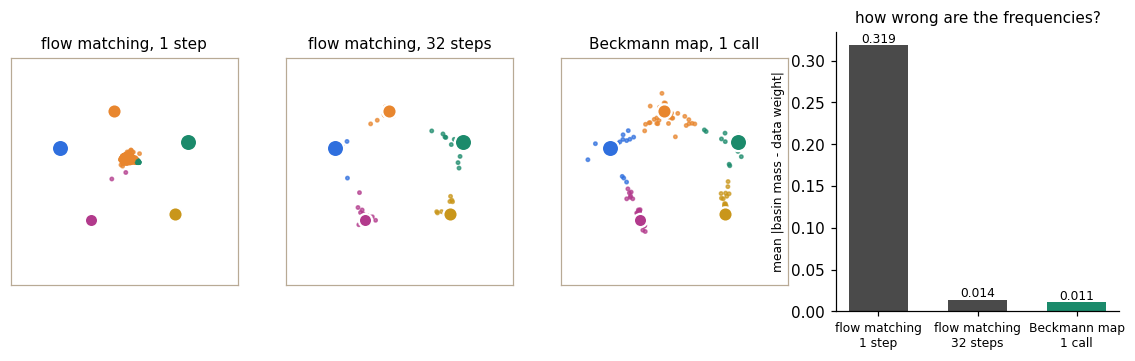

In [10]:
def mass_error(x): return np.abs(basin_masses(x) - P).mean()
fig, axs = plt.subplots(1, 4, figsize=(13, 3.3), gridspec_kw={"width_ratios": [1, 1, 1, 1.25]})
runs = [("flow matching, 1 step", euler(X0, 1).numpy(), CHARCOAL), ("flow matching, 32 steps", euler(X0, 32).numpy(), CHARCOAL), ("Beckmann map, 1 call", xs, SAGE)]
for ax, (name, x, c) in zip(axs, runs):
    ax.scatter(*x.T, s=5, c=[COL[k] for k in nearest_atom(x)], alpha=.7); draw_atoms(ax, label=False); frame(ax, name)
ax = axs[3]; names = [r[0].replace(", ", "\n") for r in runs]; errs = [mass_error(r[1]) for r in runs]
ax.bar(range(3), errs, color=[r[2] for r in runs], width=.6); ax.set_xticks(range(3)); ax.set_xticklabels(names, fontsize=8)
ax.set_ylabel("mean |basin mass - data weight|", fontsize=8); ax.set_title("how wrong are the frequencies?", fontsize=10)
for i, e in enumerate(errs): ax.text(i, e + .003, f"{e:.3f}", ha="center", fontsize=8)
plt.show()

## 7. Bonus: guidance in one picture (what SBM adds)

Real models are **conditional**: the map takes a class label or a text prompt $c$, and through *condition dropout* the same network also learns a *null* branch $T_\emptyset$ that ignores it. Multistep models get much of their quality from **classifier-free guidance**: they push the sample away from the null prediction and toward the conditional one, with a strength $\omega \ge 1$. A map has no velocity or score to guide, only endpoint predictions.

The observation behind SBM is that the current is a **denoising field**: $J_c(x) = h_c(x)\,(\bar z_c(x) - x)$ with $h_c > 0$, where $\bar z_c$ is a weighted posterior mean of the data. Classifier-free guidance applies to such a field as it does to a velocity, and substituting the map's own two predictions for the denoisers gives the **guided transport direction**

$$\dot I^{\omega}_t = \dot I_t + \frac{1 - \omega^{-1}}{1 - t}\,\big(T(I_t, c) - T_\emptyset(I_t)\big),$$

used in place of $\dot I_t$ in the transport loss, with the matching correction $x_1 + (1 - \omega^{-1})\big(T(x_1, c) - T_\emptyset(x_1)\big)$ as the boundary target. No second network, and sampling is still one call. Where the conditional and null predictions disagree, the current is bent toward the mode the condition favours, and the **basin boundaries move**: the condition's typical modes gain mass, the ambiguous ones lose it. At $\omega = 1$ everything reduces to the plain Beckmann map.

Toy version: two classes share the five points. Class $c$ puts weights $p = (0.45, 0.30, 0.25, 0, 0)$ on them, the other class $q = (0, 0, 0.5, 0.25, 0.25)$; with class prior $\pi = 0.3$ the null (unconditional) law is $\nu = \pi p + (1 - \pi) q = (0.135, 0.09, 0.425, 0.175, 0.175)$. Point 2 is *ambiguous*: class $c$ uses it, but the null law uses it far more, so the null branch predicts point 2 in places where the class branch predicts point 0 or 1. Guidance should move class-$c$ mass away from point 2, toward points 0 and 1, in the direction of the usual CFG tilt $w_j \propto p_j^{\omega}\,\nu_j^{1 - \omega}$. We first train the conditional map at $\omega = 1$, then fine-tune it with guidance at $\omega = 3$; as in the paper, a frozen copy of the network provides the conditional and null predictions in the correction, and for this toy the correction is applied on a band of interpolation times (guiding at every time collapses the map in two dimensions).

conditional Beckmann map, omega = 1
step  1000   loss 36.6086   (16 s)
step  2000   loss 47.7864   (32 s)
step  3000   loss 50.1318   (48 s)
step  4000   loss 77.6635   (64 s)
step  5000   loss 51.9816   (80 s)
step  6000   loss 50.7112   (97 s)
step  7000   loss 67.8165   (113 s)
step  8000   loss 56.7512   (129 s)
guided fine-tuning, omega = 3
step  1000   loss 55.6092   (22 s)
step  2000   loss 102.1748   (45 s)
step  3000   loss 120.0543   (69 s)
step  4000   loss 74.5527   (93 s)
step  5000   loss 125.0830   (117 s)
step  6000   loss 243.4706   (141 s)
step  7000   loss 227.9978   (165 s)
step  8000   loss 137.7410   (189 s)
class-c basin masses   omega = 1: [0.42 0.32 0.26 0.   0.  ]   data weights p: [0.45 0.3  0.25 0.   0.  ]
                       omega = 3: [0.51 0.27 0.22 0.   0.  ]   CFG tilt reference: [0.59 0.4  0.01 0.   0.  ]


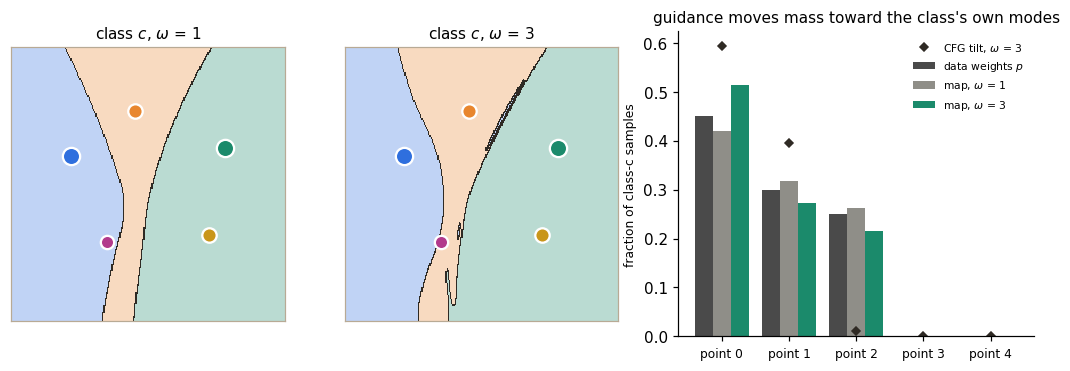

In [11]:
PC = np.array([.45, .30, .25, 0, 0]); PQ = np.array([0, 0, .5, .25, .25]); PI = 0.3; NU_NULL = PI * PC + (1 - PI) * PQ
def tilt(omega): w = PC ** omega * np.where(NU_NULL > 0, NU_NULL, 1) ** (1 - omega) * (NU_NULL > 0); return w / w.sum()
def cond_batch(n, p_drop=0.5):   # labels: 0 = class c, 1 = the other class, 2 = null (condition dropout)
    y = (np.random.rand(n) < PI).astype(int) ^ 1          # 0 with probability PI
    k = np.where(y == 0, np.random.choice(J, n, p=PC), np.random.choice(J, n, p=PQ))
    lab = np.where(np.random.rand(n) < p_drop, 2, y)
    x0 = torch.randn(n, 2); x1 = torch.as_tensor(Z[k], dtype=torch.float32); t = torch.rand(n, 1); s = GAMMA + (1 - GAMMA) * torch.rand(n, 1)
    return x0, x1, t, (1 - t) * x0 + t * x1, x1 - x0, (1 - s) * x0 + s * x1, torch.nn.functional.one_hot(torch.as_tensor(lab), 3).float()
NULL = torch.nn.functional.one_hot(torch.tensor(2), 3).float()

Tc = Map(dcond=3)
def cond_loss(step):
    x0, x1, t, I, Idot, Ib, c = cond_batch(2048)
    with torch.no_grad(): T_I, dT = torch.func.jvp(lambda x: Tc(x, c), (I,), (Idot,)); target = T_I + dT
    return ((Tc(I, c) - target) ** 2).sum(-1).mean() + LAM * ((Tc(Ib, c) - x1) ** 2).sum(-1).mean()
print("conditional Beckmann map, omega = 1"); fit(cond_loss, Tc.parameters(), 8000, lr=3e-4)

@torch.no_grad()
def class_c(model, x0):
    x0 = torch.as_tensor(x0, dtype=torch.float32); c = torch.nn.functional.one_hot(torch.zeros(len(x0), dtype=torch.long), 3).float()
    return model(x0, c).numpy()
m1 = basin_masses(class_c(Tc, X0.numpy()))

OMEGA, BAND = 3.0, (0.35, 0.6)
Tg2 = copy.deepcopy(Tc); teacher = copy.deepcopy(Tc).requires_grad_(False)
def guided_loss(step):
    if step % 2000 == 1: teacher.load_state_dict(Tg2.state_dict())
    x0, x1, t, I, Idot, Ib, c = cond_batch(2048)
    with torch.no_grad():
        cond = (c[:, 2] == 0).float()[:, None]                                  # guide the conditional rows only
        band = ((t >= BAND[0]) & (t <= BAND[1])).float()
        null = NULL.expand(len(I), 3)
        corr = (1 - 1 / OMEGA) * (teacher(I, c) - teacher(I, null))             # conditional - null disagreement at I_t
        Idot_w = Idot + cond * band * corr / (1 - t)                            # the guided transport direction
        T_I, dT = torch.func.jvp(lambda x: Tg2(x, c), (I,), (Idot_w,)); target = T_I + dT
        bd_target = x1 + cond * (1 - 1 / OMEGA) * (teacher(Ib, c) - teacher(Ib, null))
    return ((Tg2(I, c) - target) ** 2).sum(-1).mean() + LAM * ((Tg2(Ib, c) - bd_target) ** 2).sum(-1).mean()
print(f"guided fine-tuning, omega = {OMEGA:g}"); fit(guided_loss, Tg2.parameters(), 8000, lr=3e-4)
m2 = basin_masses(class_c(Tg2, X0.numpy()))

print("class-c basin masses   omega = 1:", np.round(m1, 2), "  data weights p:", PC)
print(f"                       omega = {OMEGA:g}:", np.round(m2, 2), "  CFG tilt reference:", np.round(tilt(OMEGA), 2))
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for ax, model, name in zip(axs, [Tc, Tg2], [r"class $c$, $\omega$ = 1", rf"class $c$, $\omega$ = {OMEGA:g}"]):
    L = nearest_atom(class_c(model, grid)).reshape(NB, NB)
    ax.imshow(L.T, origin="lower", extent=(-2.5, 2.5, -2.5, 2.5), cmap=TINTS, vmin=-.5, vmax=J - .5, interpolation="nearest")
    Eg = basin_edges(L); ax.imshow(np.ma.masked_where(~Eg, Eg).T, origin="lower", extent=(-2.5, 2.5, -2.5, 2.5), cmap=ListedColormap([INK]), interpolation="nearest")
    draw_atoms(ax, label=False); frame(ax, name)
ax = axs[2]; w = .27; ks_ = np.arange(J)
ax.bar(ks_ - w, PC, w, color=CHARCOAL, label=r"data weights $p$"); ax.bar(ks_, m1, w, color=GREY, label=r"map, $\omega$ = 1"); ax.bar(ks_ + w, m2, w, color=SAGE, label=rf"map, $\omega$ = {OMEGA:g}")
ax.plot(ks_, tilt(OMEGA), "D", color=INK, ms=4, label=rf"CFG tilt, $\omega$ = {OMEGA:g}"); ax.set_xticks(ks_); ax.set_xticklabels([f"point {j}" for j in ks_], fontsize=8)
ax.set_ylabel("fraction of class-c samples", fontsize=8); ax.legend(fontsize=7, frameon=False); ax.set_title("guidance moves mass toward the class's own modes", fontsize=10)
plt.show()

Guidance moved the basin boundaries of the conditional map: the class's dominant point gains mass and the ambiguous point loses it, in the direction of the CFG tilt though not all the way. Which points gain is set by the geometry of the two branches' disagreement, not by the likelihood ratio alone. On ImageNet this is the ingredient that takes the one-step map from a FID in the twenties to 1.6.

## 8. What scales it

The recipe that trains maps with hundreds of millions of parameters (Algorithm 2 of the paper) keeps exactly the two losses above and adds engineering around the stop-gradient: a frozen copy of the network for the stopped targets, a per-row normalization of the transport term, an adaptive balance between the transport and boundary gradients, a mixture of interpolation times, and a *boundary level* $\gamma$ that lets the boundary term see slightly noisy data. With those, a Beckmann map trained from scratch in the latent space of a representation autoencoder reaches a one-step FID of 1.6 on ImageNet 256, a GenEval score of 0.86 in text-to-image generation, and beats DriftWorld on two robot world-modelling benchmarks, all with one network evaluation per sample and no teacher.

Where to go next:

- the [project page](https://tullebulle.github.io/projects/sbm/), with the interactive tutorial, the animations and a live text-to-image demo;
- *Beckmann Transport Models* (Lee et al., 2026) for the autonomous-flow theory, and *Scalable Beckmann Maps improve one-step generation* (Unneberg, Wang et al., 2026) for guidance, the recipe and the proofs.